In [1]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Optional, Tuple, Dict

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
from __future__ import annotations

import re
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Optional, Tuple

import numpy as np
import xarray as xr

# plotting (optional)
import matplotlib.pyplot as plt


@dataclass(frozen=True)
class RmmVerifyConfig:
    # Your saved EOF/RMM file
    eof_nc: str

    # Raw obs files (same ones used to build EOFs)
    noaa_olr_file: str
    era5_u850_file: str
    era5_u200_file: str

    # Variable names
    v_olr: str = "FLUT"
    v_u850: str = "U850"
    v_u200: str = "U200"

    # Coordinate names used in your EOF file (should be lat/lon/time)
    time_dim: str = "time"
    lat_dim: str = "lat"
    lon_dim: str = "lon"

    # Domain/time (should match training)
    train_start: str = "1986-01-01"
    train_end: str = "2017-12-31"
    lat_range: Tuple[float, float] = (-15.0, 15.0)
    lon_range: Tuple[float, float] = (0.0, 360.0)

    # preprocessing choices (should match the EOF file attrs)
    # NOTE: if these disagree with ds_eof.attrs, self-projection will degrade.
    drop_leap_day: bool = True
    doy_smooth_days: int = 31
    lowfreq_rm_days: int = 120

    # optional: only verify a smaller slice (faster)
    verify_start: Optional[str] = None
    verify_end: Optional[str] = None

    # plotting
    figsize: Tuple[float, float] = (11, 4)
    out_dir: Optional[str] = None


class RmmObsVerifier:
    """
    Verify a saved observed EOF + RMM file by re-computing anomalies from raw obs
    and projecting onto the saved EOFs, then comparing with saved RMM1/RMM2.

    Consistency requirements (must match builder):
      - time normalized to daily 00Z (datetime64[D] floored)
      - lon converted to 0..360
      - lon range selection uses strict < 360 when lon_range end >= 360 (avoid 0/360 duplicate)
      - DOY climatology uses contiguous doy365 (1..365) after dropping Feb 29
      - lowfreq removal via centered running mean
      - lat weighting sqrt(cos(lat))
      - divide each variable by saved norm_std_* scalars
      - projection scaling: divide by pc_std_mode (mode-wise) then by rmm_scale
        (exactly mirroring builder output)
    """

    def __init__(self, cfg: RmmVerifyConfig):
        self.cfg = cfg
        self.ds_eof = xr.open_dataset(cfg.eof_nc)

    # -------------------------
    # Helpers: IO / subsetting
    # -------------------------
    def _normalize_time_to_00z(self, da: xr.DataArray) -> xr.DataArray:
        cfg = self.cfg
        t00 = np.array(da[cfg.time_dim].values, dtype="datetime64[D]").astype("datetime64[ns]")
        return da.assign_coords({cfg.time_dim: t00})

    def _ensure_lon_0_360(self, da: xr.DataArray) -> xr.DataArray:
        cfg = self.cfg
        lon = da[cfg.lon_dim]
        if lon.min() < 0:
            da = da.assign_coords({cfg.lon_dim: (lon % 360).astype(lon.dtype)}).sortby(cfg.lon_dim)
        return da

    def _subset_domain_time(self, da: xr.DataArray) -> xr.DataArray:
        cfg = self.cfg
        da = self._normalize_time_to_00z(da)
        da = self._ensure_lon_0_360(da)

        # domain
        lat0, lat1 = cfg.lat_range
        lon0, lon1 = cfg.lon_range

        lat = da[cfg.lat_dim]
        if lat[0] < lat[-1]:
            da = da.sel({cfg.lat_dim: slice(lat0, lat1)})
        else:
            da = da.sel({cfg.lat_dim: slice(lat1, lat0)})

        lon = da[cfg.lon_dim]
        if lon1 >= 360.0:
            # strict < 360 to avoid duplicated 0/360 if 360 exists in coordinate
            m = (lon >= lon0) & (lon < 360.0)
            da = da.sel({cfg.lon_dim: lon.where(m, drop=True)})
        else:
            da = da.sel({cfg.lon_dim: slice(lon0, lon1)})

        # time
        start = cfg.verify_start or cfg.train_start
        end = cfg.verify_end or cfg.train_end
        da = da.sel({cfg.time_dim: slice(start, end)})

        # drop duplicate times (can appear after flooring to day)
        t = da[cfg.time_dim].values
        _, idx = np.unique(t, return_index=True)
        if idx.size != t.size:
            da = da.isel({cfg.time_dim: np.sort(idx)})

        return da.sortby(cfg.time_dim)

    def _select_pressure_level_if_needed(self, da: xr.DataArray, var: str, path: str) -> xr.DataArray:
        """
        Mirror builder logic: support common ERA5 conventions
        - level: hPa
        - plev : Pa
        Choose target based on digits in var or filename (e.g., U850, U200).
        """
        def infer_target_hpa() -> Optional[int]:
            m = re.search(r"(\d{3,4})", var)
            if m:
                return int(m.group(1))
            fname = Path(path).name
            m2 = re.search(r"(\d{3,4})", fname)
            if m2:
                return int(m2.group(1))
            return None

        target_hpa = infer_target_hpa()

        if "level" in da.dims:
            if da.sizes["level"] == 1:
                return da.isel(level=0, drop=True)
            if target_hpa is None:
                return da.isel(level=0, drop=True)
            da = da.sel(level=target_hpa, method="nearest")
            if "level" in da.dims and da.sizes["level"] == 1:
                da = da.isel(level=0, drop=True)
            return da

        if "plev" in da.dims:
            if da.sizes["plev"] == 1:
                return da.isel(plev=0, drop=True)
            if target_hpa is None:
                return da.isel(plev=0, drop=True)
            target_pa = float(target_hpa) * 100.0
            da = da.sel(plev=target_pa, method="nearest")
            if "plev" in da.dims and da.sizes["plev"] == 1:
                da = da.isel(plev=0, drop=True)
            return da

        return da

    def _open_var(self, path: str, var: str) -> xr.DataArray:
        cfg = self.cfg
        ds = xr.open_dataset(path)
        if var not in ds:
            raise KeyError(f"Variable '{var}' not found in {path}. Vars: {list(ds.data_vars)}")
        da = ds[var]

        # ERA5 may use latitude/longitude
        rename_map = {}
        if "latitude" in da.dims and cfg.lat_dim not in da.dims:
            rename_map["latitude"] = cfg.lat_dim
        if "longitude" in da.dims and cfg.lon_dim not in da.dims:
            rename_map["longitude"] = cfg.lon_dim
        if rename_map:
            da = da.rename(rename_map)

        # Select level/plev if needed (robust)
        da = self._select_pressure_level_if_needed(da, var, path)

        # Ensure dim order
        da = da.transpose(cfg.time_dim, cfg.lat_dim, cfg.lon_dim)
        return da

    # -------------------------
    # Preprocessing
    # -------------------------
    def _drop_leap_day(self, da: xr.DataArray) -> xr.DataArray:
        cfg = self.cfg
        if not cfg.drop_leap_day:
            return da
        t = da[cfg.time_dim]
        mask = ~((t.dt.month == 2) & (t.dt.day == 29))
        return da.sel({cfg.time_dim: mask})

    def _add_doy365_coord(self, da: xr.DataArray) -> xr.DataArray:
        """
        Add contiguous 1..365 DOY coordinate after (optional) dropping Feb 29.
        Leap years: days after Feb 28 shift down by 1.
        """
        cfg = self.cfg
        t = da[cfg.time_dim]
        doy = t.dt.dayofyear
        is_leap = t.dt.is_leap_year
        doy365 = xr.where(is_leap & (doy > 59), doy - 1, doy)
        return da.assign_coords(doy365=doy365)

    def _smooth_doy_climo_365(self, climo: xr.DataArray, win: int) -> xr.DataArray:
        """
        Smooth climatology across doy365 with wraparound using rolling mean.
        climo dims: doy365, lat, lon with doy365=1..365 contiguous.
        """
        if win is None or win <= 1:
            return climo

        doy = climo["doy365"]
        n = int(doy.max())
        pad = win // 2

        left = climo.sel(doy365=slice(n - pad + 1, n))
        right = climo.sel(doy365=slice(1, pad))

        padded = xr.concat([left, climo, right], dim="doy365")
        padded = padded.assign_coords(doy365=np.arange(1, padded.sizes["doy365"] + 1))

        sm = padded.rolling(doy365=win, center=True, min_periods=win).mean()
        sm = sm.isel(doy365=slice(pad, pad + n))
        sm = sm.assign_coords(doy365=np.arange(1, n + 1))
        return sm

    def _doy_anomaly(self, da: xr.DataArray) -> xr.DataArray:
        """
        DOY anomalies using contiguous doy365 coordinate (matches revised builder).
        """
        cfg = self.cfg
        da = self._drop_leap_day(da)
        da = self._add_doy365_coord(da)

        climo = da.groupby("doy365").mean(cfg.time_dim)
        if cfg.doy_smooth_days and cfg.doy_smooth_days > 1:
            climo = self._smooth_doy_climo_365(climo, cfg.doy_smooth_days)

        return da.groupby("doy365") - climo

    def _remove_lowfreq(self, anom: xr.DataArray) -> xr.DataArray:
        cfg = self.cfg
        w = cfg.lowfreq_rm_days
        if w is None or w <= 1:
            return anom
        low = anom.rolling({cfg.time_dim: w}, center=True, min_periods=w).mean()
        return anom - low

    def _lat_weight(self, da: xr.DataArray) -> xr.DataArray:
        cfg = self.cfg
        lat = da[cfg.lat_dim]
        w = np.sqrt(np.cos(np.deg2rad(lat)))
        return da * w

    def _apply_obs_norms(self, da: xr.DataArray, which: str) -> xr.DataArray:
        """
        Divide by the normalization scalars saved in eof file:
          norm_std_olr, norm_std_u850, norm_std_u200
        """
        ds = self.ds_eof
        if which == "olr":
            s = float(ds["norm_std_olr"].values)
        elif which == "u850":
            s = float(ds["norm_std_u850"].values)
        elif which == "u200":
            s = float(ds["norm_std_u200"].values)
        else:
            raise ValueError(which)
        if not np.isfinite(s) or s == 0.0:
            raise ValueError(f"Bad normalization scalar for {which}: {s}")
        return da / s

    def preprocess_for_projection(self, da: xr.DataArray, which: str) -> xr.DataArray:
        """
        Full preprocessing for projection (matches revised builder):
          - DOY anomaly (doy365, optional smoothing)
          - subtract centered running mean (lowfreq_rm_days)
          - sqrt(cos(lat))
          - divide by obs normalization scalar (saved in eof file)
        """
        da = self._doy_anomaly(da)
        da = self._remove_lowfreq(da)
        da = self._lat_weight(da)
        da = self._apply_obs_norms(da, which)
        return da

    # -------------------------
    # Core checks
    # -------------------------
    def check_file_structure(self) -> None:
        ds = self.ds_eof
        required = ["EOF_OLR", "EOF_U850", "EOF_U200", "RMM1", "RMM2", "rmm_scale", "pc_std_mode"]
        missing = [v for v in required if v not in ds]
        if missing:
            raise KeyError(f"Missing in EOF file: {missing}")

        # Basic shape checks
        for v in ["EOF_OLR", "EOF_U850", "EOF_U200"]:
            if set(ds[v].dims) != {"mode", self.cfg.lat_dim, self.cfg.lon_dim}:
                raise ValueError(f"{v} dims are {ds[v].dims}, expected ('mode','lat','lon')")

        # time monotonic
        t = ds["RMM1"][self.cfg.time_dim].values
        if not np.all(np.diff(t.astype("datetime64[ns]").astype("int64")) > 0):
            print("WARNING: RMM time is not strictly increasing (check duplicates).")

        # config consistency warnings (non-fatal)
        attrs = ds.attrs
        if "doy_smooth_days" in attrs:
            try:
                a = int(str(attrs["doy_smooth_days"]))
                if a != int(self.cfg.doy_smooth_days):
                    print(f"WARNING: cfg.doy_smooth_days={self.cfg.doy_smooth_days} != ds.attrs['doy_smooth_days']={a}")
            except Exception:
                pass
        if "lowfreq_rm_days" in attrs:
            try:
                a = int(str(attrs["lowfreq_rm_days"]))
                if a != int(self.cfg.lowfreq_rm_days):
                    print(f"WARNING: cfg.lowfreq_rm_days={self.cfg.lowfreq_rm_days} != ds.attrs['lowfreq_rm_days']={a}")
            except Exception:
                pass
        if "drop_leap_day" in attrs:
            try:
                a = str(attrs["drop_leap_day"]).lower() in ("true", "1", "yes")
                if a != bool(self.cfg.drop_leap_day):
                    print(f"WARNING: cfg.drop_leap_day={self.cfg.drop_leap_day} != ds.attrs['drop_leap_day']={a}")
            except Exception:
                pass

    def check_eof_orthogonality(self) -> Dict[str, float]:
        ds = self.ds_eof
        e1 = np.concatenate([
            ds.EOF_OLR.sel(mode=1).values.ravel(),
            ds.EOF_U850.sel(mode=1).values.ravel(),
            ds.EOF_U200.sel(mode=1).values.ravel(),
        ])
        e2 = np.concatenate([
            ds.EOF_OLR.sel(mode=2).values.ravel(),
            ds.EOF_U850.sel(mode=2).values.ravel(),
            ds.EOF_U200.sel(mode=2).values.ravel(),
        ])
        dot = float(np.dot(e1, e2))
        nrm = float(np.linalg.norm(e1) * np.linalg.norm(e2))
        return {"dot": dot, "normalized_dot": dot / nrm if nrm > 0 else np.nan}

    def project_obs_and_compare(self) -> Dict[str, float]:
        """
        Recompute PCs by projecting processed obs anomalies onto saved EOFs,
        then compare to ds_eof['RMM1','RMM2'].

        IMPORTANT:
          The saved EOFs are in the same normalized feature space used for SVD.
          Therefore, after pc_raw = X @ EOF, we must apply the same PC scaling
          used in the builder: divide by pc_std_mode then by rmm_scale.
        """
        cfg = self.cfg
        ds_eof = self.ds_eof

        # Load raw
        olr = self._subset_domain_time(self._open_var(cfg.noaa_olr_file, cfg.v_olr))
        u850 = self._subset_domain_time(self._open_var(cfg.era5_u850_file, cfg.v_u850))
        u200 = self._subset_domain_time(self._open_var(cfg.era5_u200_file, cfg.v_u200))

        # Common time (after 00Z normalize)
        common = np.intersect1d(olr[cfg.time_dim].values, u850[cfg.time_dim].values)
        common = np.intersect1d(common, u200[cfg.time_dim].values)
        common = np.intersect1d(common, ds_eof[cfg.time_dim].values)

        if common.size < 1000:
            raise ValueError(f"Too few common days for verification: {common.size}")

        olr = olr.sel({cfg.time_dim: common}).sortby(cfg.time_dim)
        u850 = u850.sel({cfg.time_dim: common}).sortby(cfg.time_dim)
        u200 = u200.sel({cfg.time_dim: common}).sortby(cfg.time_dim)

        # Preprocess (matches builder)
        olr_p = self.preprocess_for_projection(olr, "olr")
        u850_p = self.preprocess_for_projection(u850, "u850")
        u200_p = self.preprocess_for_projection(u200, "u200")

        # Drop times with NaNs (lowfreq edges)
        ok = (
            np.isfinite(olr_p).all(dim=(cfg.lat_dim, cfg.lon_dim)) &
            np.isfinite(u850_p).all(dim=(cfg.lat_dim, cfg.lon_dim)) &
            np.isfinite(u200_p).all(dim=(cfg.lat_dim, cfg.lon_dim))
        )
        olr_p = olr_p.sel({cfg.time_dim: ok})
        u850_p = u850_p.sel({cfg.time_dim: ok})
        u200_p = u200_p.sel({cfg.time_dim: ok})

        time = olr_p[cfg.time_dim].values

        # Stack features
        olr_s = olr_p.stack(feature=(cfg.lat_dim, cfg.lon_dim))
        u850_s = u850_p.stack(feature=(cfg.lat_dim, cfg.lon_dim))
        u200_s = u200_p.stack(feature=(cfg.lat_dim, cfg.lon_dim))

        X = np.concatenate([olr_s.values, u850_s.values, u200_s.values], axis=1).astype("float64", copy=False)

        # Build EOF vectors (feature space)
        eof1 = np.concatenate([
            ds_eof.EOF_OLR.sel(mode=1).values.ravel(),
            ds_eof.EOF_U850.sel(mode=1).values.ravel(),
            ds_eof.EOF_U200.sel(mode=1).values.ravel(),
        ]).astype("float64", copy=False)

        eof2 = np.concatenate([
            ds_eof.EOF_OLR.sel(mode=2).values.ravel(),
            ds_eof.EOF_U850.sel(mode=2).values.ravel(),
            ds_eof.EOF_U200.sel(mode=2).values.ravel(),
        ]).astype("float64", copy=False)

        # Project into raw PC space
        pc1_raw = X @ eof1
        pc2_raw = X @ eof2

        # Apply PC scaling used in builder: /pc_std_mode then /rmm_scale
        pc_std = ds_eof["pc_std_mode"].values.astype("float64")
        rmm_scale = float(ds_eof["rmm_scale"].values)
        if pc_std.shape[0] < 2 or not np.all(np.isfinite(pc_std)):
            raise ValueError(f"Bad pc_std_mode in EOF file: {pc_std}")
        if not np.isfinite(rmm_scale) or rmm_scale == 0.0:
            raise ValueError(f"Bad rmm_scale in EOF file: {rmm_scale}")

        pc1 = (pc1_raw / pc_std[0]) / rmm_scale
        pc2 = (pc2_raw / pc_std[1]) / rmm_scale

        # Compare to saved RMM1/RMM2 (same times)
        rmm1 = ds_eof["RMM1"].sel({cfg.time_dim: time}).values.astype("float64")
        rmm2 = ds_eof["RMM2"].sel({cfg.time_dim: time}).values.astype("float64")

        def _corr(a, b):
            a = a - np.nanmean(a)
            b = b - np.nanmean(b)
            den = np.sqrt(np.nanmean(a * a)) * np.sqrt(np.nanmean(b * b))
            return float(np.nanmean(a * b) / den) if den > 0 else np.nan

        def _rmse(a, b):
            d = a - b
            return float(np.sqrt(np.nanmean(d * d)))

        # allow sign flip ambiguity: choose sign that maximizes corr for each mode
        c1 = _corr(pc1, rmm1)
        c1n = _corr(-pc1, rmm1)
        sign1 = -1.0 if c1n > c1 else 1.0
        pc1 *= sign1
        c1 = max(c1, c1n)

        c2 = _corr(pc2, rmm2)
        c2n = _corr(-pc2, rmm2)
        sign2 = -1.0 if c2n > c2 else 1.0
        pc2 *= sign2
        c2 = max(c2, c2n)

        # extra hard constraint check (should be ~1): mean(RMM1^2 + RMM2^2)
        mss = float(np.nanmean(rmm1 * rmm1 + rmm2 * rmm2))

        return dict(
            n_days=int(time.size),
            corr_rmm1=c1,
            corr_rmm2=c2,
            rmse_rmm1=_rmse(pc1, rmm1),
            rmse_rmm2=_rmse(pc2, rmm2),
            sign_rmm1=sign1,
            sign_rmm2=sign2,
            mean_rmm1sq_rmm2sq=mss,
        )

    def amp_phase_stats(self) -> Dict[str, float]:
        cfg = self.cfg
        ds = self.ds_eof
        rmm1 = ds["RMM1"]
        rmm2 = ds["RMM2"]
        amp = np.sqrt(rmm1**2 + rmm2**2)
        phase = (np.arctan2(rmm2, rmm1) * 180.0 / np.pi) % 360.0

        start = cfg.verify_start or cfg.train_start
        end = cfg.verify_end or cfg.train_end
        amp = amp.sel({cfg.time_dim: slice(start, end)})
        phase = phase.sel({cfg.time_dim: slice(start, end)})

        return dict(
            amp_mean=float(amp.mean().values),
            amp_std=float(amp.std().values),
            phase_mean_deg=float(phase.mean().values),
        )

    # -------------------------
    # Plotting (optional)
    # -------------------------
    def plot_eofs(self, mode: int = 1) -> None:
        cfg = self.cfg
        ds = self.ds_eof
        fig, axs = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
        ds.EOF_OLR.sel(mode=mode).plot(ax=axs[0])
        axs[0].set_title(f"EOF{mode} OLR")
        ds.EOF_U850.sel(mode=mode).plot(ax=axs[1])
        axs[1].set_title(f"EOF{mode} U850")
        ds.EOF_U200.sel(mode=mode).plot(ax=axs[2])
        axs[2].set_title(f"EOF{mode} U200")
        plt.show()

    def plot_phase_space(self, start: Optional[str] = None, end: Optional[str] = None, nmax: int = 5000) -> None:
        cfg = self.cfg
        ds = self.ds_eof
        start = start or cfg.train_start
        end = end or cfg.train_end
        rmm1 = ds["RMM1"].sel({cfg.time_dim: slice(start, end)}).values
        rmm2 = ds["RMM2"].sel({cfg.time_dim: slice(start, end)}).values
        if rmm1.size > nmax:
            rmm1 = rmm1[:nmax]
            rmm2 = rmm2[:nmax]

        plt.figure(figsize=(5, 5))
        plt.plot(rmm1, rmm2, lw=0.3)
        plt.axhline(0, lw=0.8)
        plt.axvline(0, lw=0.8)
        plt.xlabel("RMM1")
        plt.ylabel("RMM2")
        plt.title("RMM phase space (subset)")
        plt.gca().set_aspect("equal", adjustable="box")
        plt.show()

    def plot_wh04_eof_panels(self, out_png: Optional[str] = None) -> plt.Figure:
        """
        WH04-style 2x3: EOF1/EOF2 for (OLR, U850, U200).
        """
        ds = self.ds_eof
        cfg = self.cfg

        fig, axs = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True)

        vars_ = [("EOF_OLR", "OLR (FLUT)"),
                 ("EOF_U850", "U850"),
                 ("EOF_U200", "U200")]

        for j, (vname, title) in enumerate(vars_):
            da1 = ds[vname].sel(mode=1)
            da2 = ds[vname].sel(mode=2)

            vabs = float(np.nanmax(np.abs(np.concatenate([da1.values.ravel(), da2.values.ravel()]))))
            vmin, vmax = -vabs, vabs

            im1 = da1.plot(ax=axs[0, j], vmin=vmin, vmax=vmax, add_colorbar=False)
            axs[0, j].set_title(f"EOF1 {title}")

            im2 = da2.plot(ax=axs[1, j], vmin=vmin, vmax=vmax, add_colorbar=False)
            axs[1, j].set_title(f"EOF2 {title}")

            cb = fig.colorbar(im1, ax=[axs[0, j], axs[1, j]], orientation="vertical", shrink=0.9)
            cb.set_label("EOF loading (arb.)")

        fig.suptitle(
            f"Observed RMM EOF patterns (train {cfg.train_start} to {cfg.train_end})\n"
            f"climo_smooth={cfg.doy_smooth_days}d, lowfreq_rm={cfg.lowfreq_rm_days}d, "
            f"lat={cfg.lat_range[0]}..{cfg.lat_range[1]}, lon={cfg.lon_range[0]}..{cfg.lon_range[1]}",
            y=1.02,
            fontsize=13,
        )

        if out_png:
            Path(out_png).parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=200, bbox_inches="tight")

        plt.show()
        return fig

    def plot_rmm_diagnostics(self, out_png: Optional[str] = None, nmax: int = 8000) -> plt.Figure:
        """
        1x3: phase space, amplitude histogram, and power spectrum.
        """
        ds = self.ds_eof
        cfg = self.cfg

        start = cfg.verify_start or cfg.train_start
        end = cfg.verify_end or cfg.train_end

        rmm1 = ds["RMM1"].sel({cfg.time_dim: slice(start, end)}).values
        rmm2 = ds["RMM2"].sel({cfg.time_dim: slice(start, end)}).values

        if rmm1.size > nmax:
            rmm1 = rmm1[:nmax]
            rmm2 = rmm2[:nmax]

        amp = np.sqrt(rmm1**2 + rmm2**2)

        fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

        axs[0].plot(rmm1, rmm2, lw=0.3)
        axs[0].axhline(0, lw=0.8)
        axs[0].axvline(0, lw=0.8)
        th = np.linspace(0, 2*np.pi, 400)
        axs[0].plot(np.cos(th), np.sin(th), lw=1.0)
        axs[0].set_aspect("equal", adjustable="box")
        axs[0].set_xlabel("RMM1")
        axs[0].set_ylabel("RMM2")
        axs[0].set_title("RMM phase space (subset)")

        axs[1].hist(amp, bins=50)
        axs[1].set_xlabel("Amplitude sqrt(RMM1^2 + RMM2^2)")
        axs[1].set_ylabel("Counts")
        axs[1].set_title("Amplitude distribution")

        x = rmm1 - np.nanmean(rmm1)
        x = x[np.isfinite(x)]
        n = x.size
        fx = np.fft.rfftfreq(n, d=1.0)
        ps = (np.abs(np.fft.rfft(x))**2) / n
        valid = fx > 0
        period = 1.0 / fx[valid]
        axs[2].plot(period, ps[valid])
        axs[2].set_xlim(2, 120)
        axs[2].set_xlabel("Period (days)")
        axs[2].set_ylabel("Power (arb.)")
        axs[2].set_title("RMM1 power spectrum")
        axs[2].set_xscale("log")

        fig.suptitle(
            f"RMM diagnostics ({start} to {end}) | climo_smooth={cfg.doy_smooth_days}d, lowfreq_rm={cfg.lowfreq_rm_days}d",
            y=1.02,
            fontsize=13,
        )

        if out_png:
            Path(out_png).parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(out_png, dpi=200, bbox_inches="tight")

        plt.show()
        return fig

    # -------------------------
    # One-call convenience
    # -------------------------
    def run_all(self, do_plots: bool = False) -> Dict[str, Dict[str, float]]:
        self.check_file_structure()
        ortho = self.check_eof_orthogonality()
        proj = self.project_obs_and_compare()
        amp = self.amp_phase_stats()

        if do_plots:
            self.plot_eofs(mode=1)
            self.plot_eofs(mode=2)
            self.plot_phase_space()

        return {"orthogonality": ortho, "self_projection": proj, "amp_phase": amp}

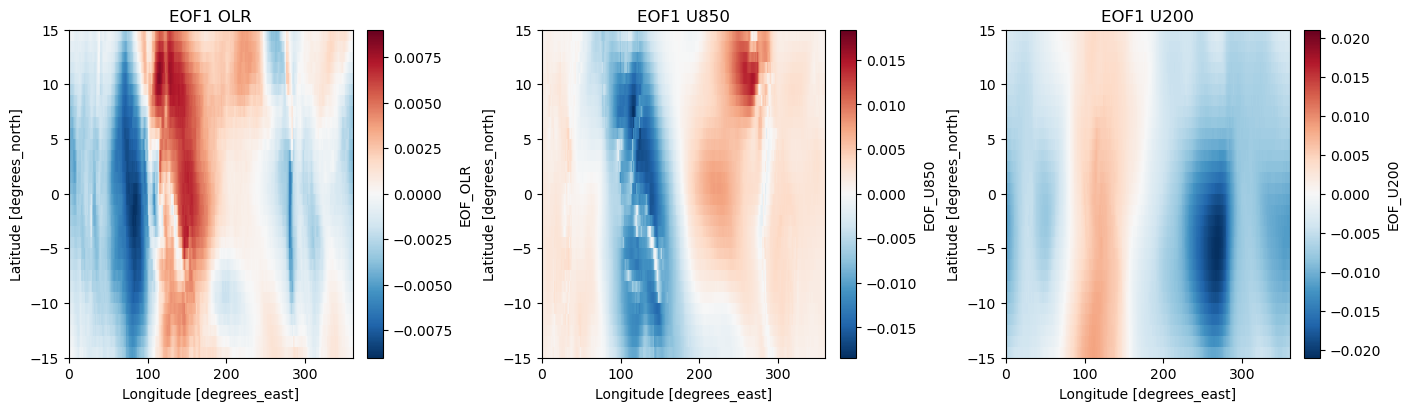

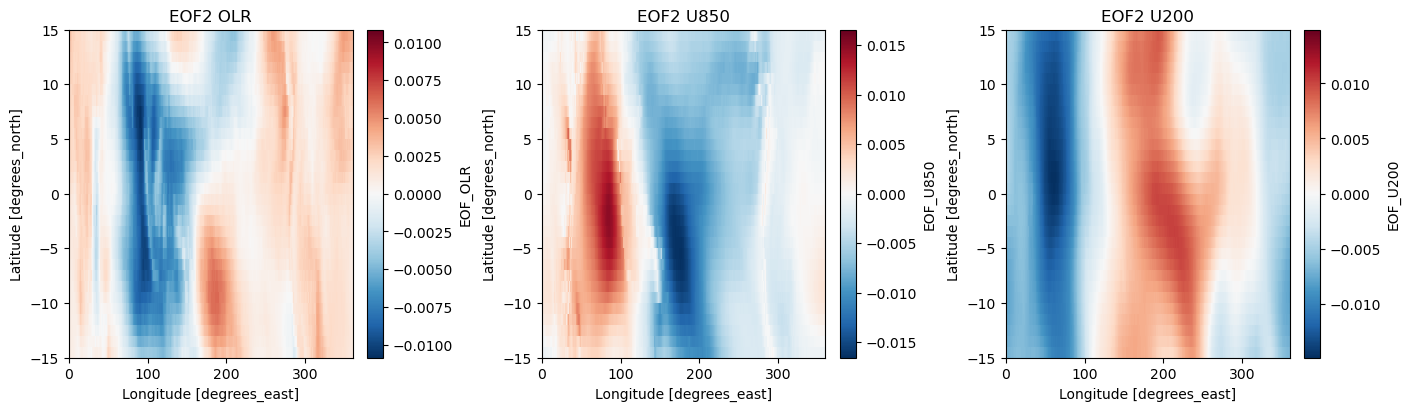

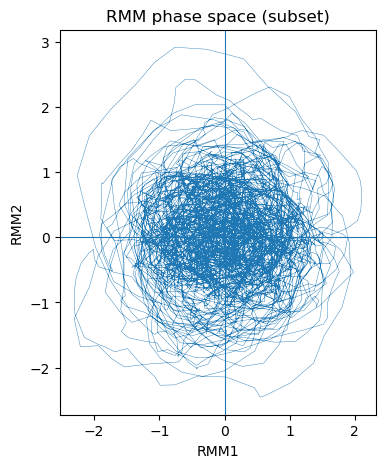

{'orthogonality': {'dot': -1.4279066817834973e-09, 'normalized_dot': -1.427906766893373e-09}, 'self_projection': {'n_days': 11442, 'corr_rmm1': 0.9997350623111372, 'corr_rmm2': 0.9997013889979818, 'rmse_rmm1': 0.016212812880670634, 'rmse_rmm2': 0.01727125530663616, 'sign_rmm1': 1.0, 'sign_rmm2': 1.0, 'mean_rmm1sq_rmm2sq': 0.995425983619916}, 'amp_phase': {'amp_mean': 0.8845953941345215, 'amp_std': 0.4663583040237427, 'phase_mean_deg': 181.57846069335938}}


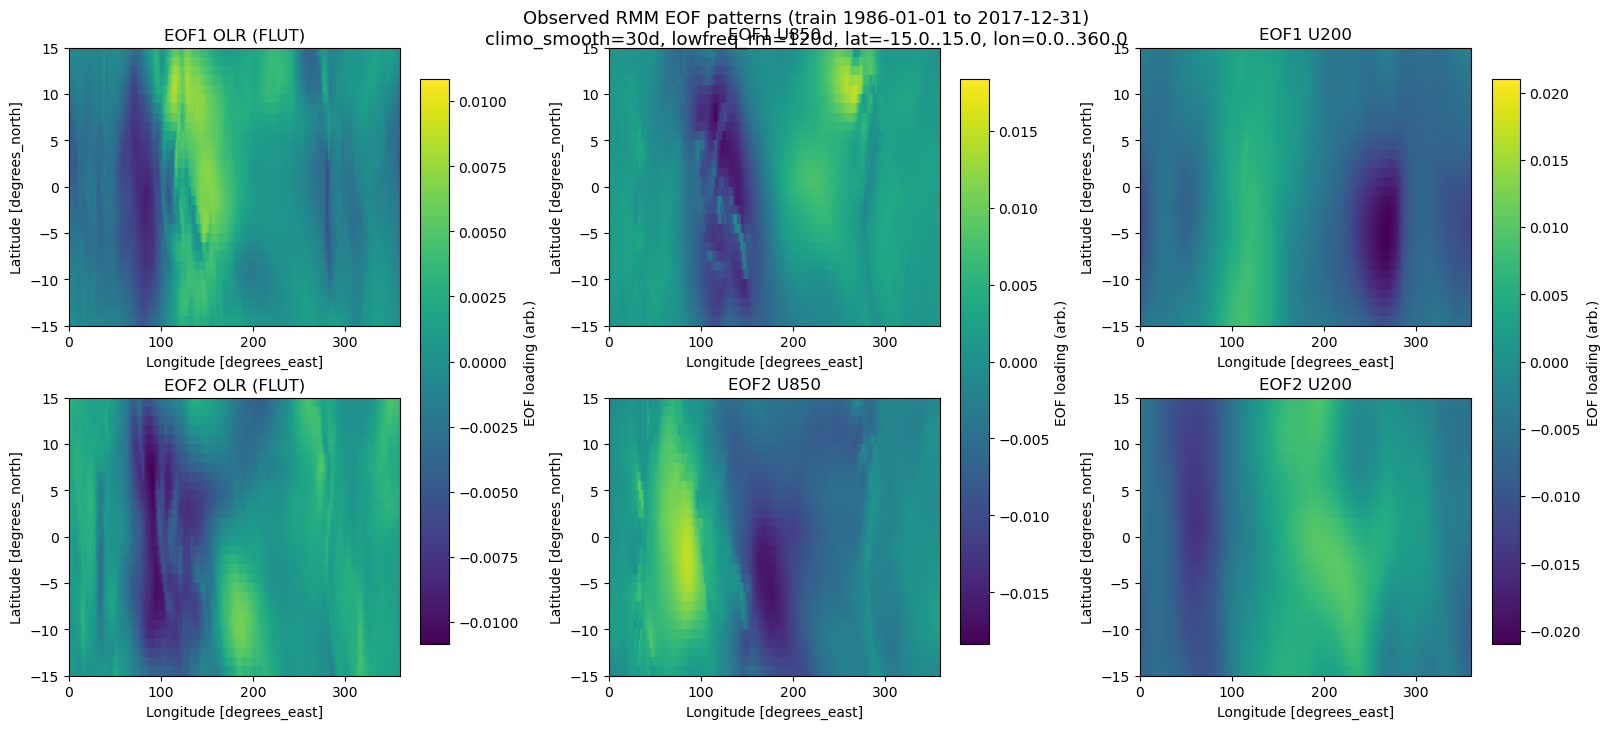

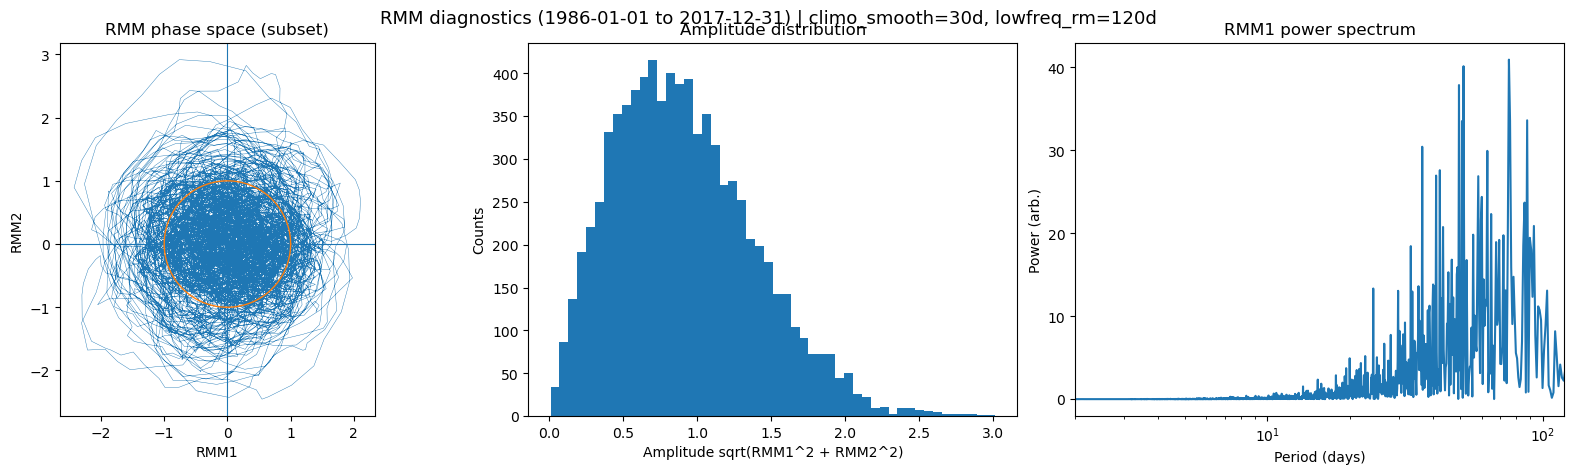

In [3]:
if __name__ == "__main__":
    work_dir = "/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper"
    diag_dir = Path(work_dir) / "figure_data" / "mjo"
    fig_dir = "./"
    
    cfgv = RmmVerifyConfig(
        eof_nc=f"{diag_dir}/rmm_obs_eof_1deg_1986-2017_climo30_rm120.nc",
        noaa_olr_file="/lcrc/soft/climate/e3sm_diags_data/obs_for_e3sm_diags/time-series/NOAA-OLR_Daily/FLUT_198601_202112.nc",
        era5_u850_file="/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/obs_data/ERA5/daily/U850_197901_201712.nc",
        era5_u200_file="/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/obs_data/ERA5/daily/U200_197901_201712.nc",
        doy_smooth_days=30,
        lowfreq_rm_days=120,
        # optional smaller window for faster verification:
        # verify_start="2008-01-01", verify_end="2012-12-31",
    )
    
    ver = RmmObsVerifier(cfgv)
    report = ver.run_all(do_plots=True)
    print(report)
    
    # WH04-style EOF figure
    ver.plot_wh04_eof_panels(out_png=str(Path(fig_dir) / "fig_rmm_eof_wh04_style.png"))
    
    # RMM diagnostics figure
    ver.plot_rmm_diagnostics(out_png=str(Path(fig_dir) / "fig_rmm_diagnostics.png"))